# Foodlytics - exploratory analysis
Olist Brazilian e-commerce data used as a **proxy** for a food-delivery platform. All numbers below are computed live from the PostgreSQL analytics layer.

In [1]:
import sys, json; from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.db import query
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.prop_cycle': plt.cycler(color=['#2a78d6', '#eb6834', '#1baf7a'])})

## 1. Raw data profile
Row counts by layer show nothing was dropped between raw and clean (except duplicate geolocation points and superseded reviews).

In [2]:
q = " UNION ALL ".join(f"SELECT '{s}.{t}' AS tbl, COUNT(*) AS n FROM {s}.{t}" for s in ['raw','clean']
      for t in ['orders','order_items','order_payments','order_reviews','customers','products','sellers','geolocation'])
query(q)

,tbl,n
0,clean.sellers,3095
1,raw.sellers,3095
2,clean.geolocation,19010
3,raw.products,32951
4,clean.products,32951
5,clean.orders,99441
6,raw.order_payments,103886
7,clean.order_payments,103886
8,clean.order_reviews,98673
9,raw.customers,99441


In [3]:
json.loads((ROOT/'data/processed/cleaning_report.json').read_text())['orders']

{'rows': 99441,
 'status_counts': {'delivered': 96478,
  'shipped': 1107,
  'canceled': 625,
  'unavailable': 609,
  'invoiced': 314,
  'processing': 301,
  'created': 5,
  'approved': 2},
 'purchase_min': '2016-09-04 21:15:19',
 'purchase_max': '2018-10-17 17:30:18',
 'flag_delivered_missing_date': 8,
 'flag_deliv_date_not_delivered': 6,
 'flag_carrier_before_approval': 1359,
 'flag_carrier_before_purchase': 166,
 'flag_delivered_before_carrier': 23,
 'flag_delivered_before_purchase': 0,
 'rows_with_any_timestamp_anomaly': 1396,
 'missing_approved_at': 160,
 'missing_carrier_date': 1783,
 'missing_delivered_date': 2965}

## 2. Is the business growing?

,orders_2017,orders_2018,orders_yoy,gmv_2017,gmv_2018,gmv_yoy,aov_2017,aov_2018,aov_yoy,customers_2017,customers_2018
0,22562,53530,1.372573,3080850.81,7341037.41,1.382795,136.55043,137.138752,0.004308,21936,52336


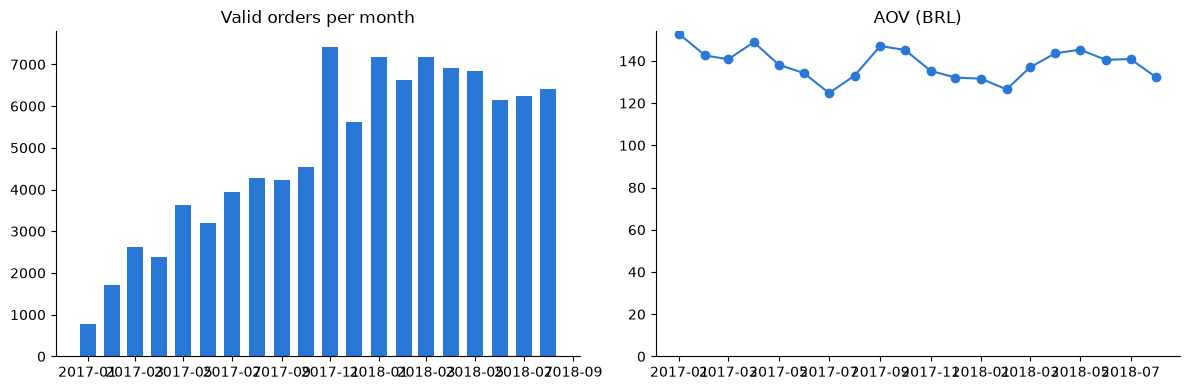

In [4]:
m = query("SELECT * FROM analytics.v_kpi_monthly")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(m.month, m.valid_orders, width=20); ax[0].set_title('Valid orders per month')
ax[1].plot(m.month, m.aov, marker='o'); ax[1].set_ylim(0); ax[1].set_title('AOV (BRL)')
plt.tight_layout(); query("SELECT * FROM analytics.v_yoy_growth")

Orders +137% YoY (Jan-Aug) while AOV is flat (+0.4%): growth is volume-driven.

In [5]:
query(open(ROOT/'sql/revenue_analysis.sql').read().split('-- name: a04_gmv_drivers')[1].split('-- name:')[0])

,abs_volume_effect,abs_value_effect,abs_interaction_effect,volume_share_of_movement,corr_gmv_change_volume,corr_gmv_change_value
0,1941848.0,528782.0,89366.0,0.759,0.961418,0.128818


## 3. Delivery vs review score (association)

In [6]:
query('SELECT * FROM analytics.v_delivery_vs_review')

,delivery_bucket,orders,avg_review_score,share_1_2_star,share_5_star
0,1. 10+ days early,61270,4.324547,0.088624,0.639840
1,2. 1-9 days early,26632,4.226720,0.099805,0.589291
2,3. on estimate day,1280,4.033594,0.124219,0.506250
3,4. 1-3 days late,1851,3.290654,0.321448,0.331713
4,5. 4-7 days late,1748,2.102975,0.676773,0.140732
5,6. 8+ days late,2779,1.696653,0.792731,0.070169


## 4. Customers: repeat behaviour and cohorts

In [7]:
query('SELECT * FROM analytics.v_customer_overview').T

,0
customers,94983.000000
repeat_customers,2063.000000
repeat_rate,0.021720
repeat_rate_order_based,0.030384
avg_purchase_days,1.024057
repeat_customer_gmv_share,0.041561
avg_customer_gmv,142.070220
avg_repeat_customer_gmv,271.856820
avg_one_time_customer_gmv,139.188712


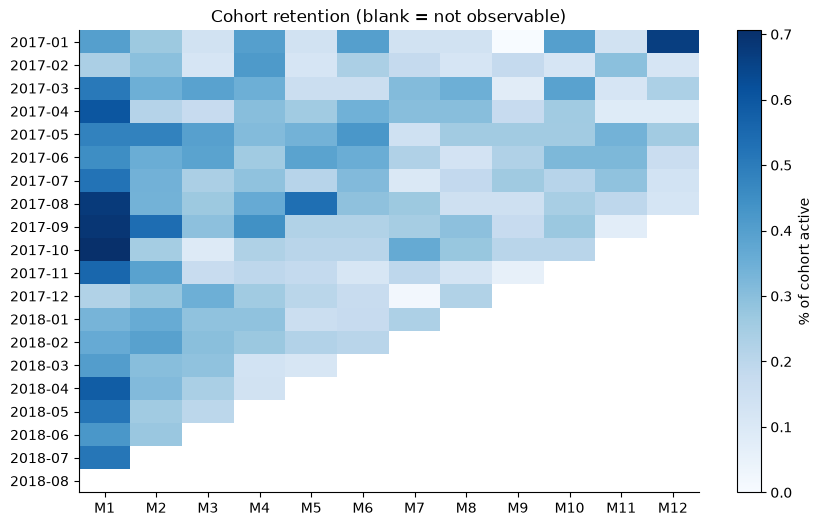

In [8]:
c = query("SELECT * FROM analytics.v_cohort_retention WHERE months_since_first BETWEEN 1 AND 12")
piv = c.pivot(index='cohort_month', columns='months_since_first', values='retention_rate') * 100
fig, ax = plt.subplots(figsize=(10, 6)); im = ax.imshow(piv.values, cmap='Blues', aspect='auto')
ax.set_yticks(range(len(piv)), [str(d)[:7] for d in piv.index]); ax.set_xticks(range(12), [f'M{k}' for k in piv.columns])
plt.colorbar(im, label='% of cohort active'); ax.set_title('Cohort retention (blank = not observable)'); plt.show()

In [9]:
query('SELECT * FROM analytics.v_repeat_within_days')

,horizon_days,eligible_customers,repeat_rate
0,30,88780,0.006679
1,60,82812,0.010325
2,90,76864,0.013075
3,180,57277,0.019903
4,365,21933,0.033374


In [10]:
query('SELECT * FROM analytics.v_customer_segments')

,segment,customers,share_customers,gmv,share_gmv,avg_gmv,avg_purchase_days,avg_recency_days,avg_first_review
0,1. Frequent (3+ purchase days),156,0.001642,68738.27,0.005094,440.629936,3.423077,154.288462,4.423077
1,2. Repeat (2 purchase days),1907,0.020077,492102.35,0.036468,258.050524,2.000000,198.078133,4.229387
2,3. High-value one-time,18067,0.190213,7225339.86,0.535438,399.919182,1.000000,245.401284,4.011500
3,4. New one-time (<=90d),14360,0.151185,1095047.61,0.081149,76.256797,1.000000,46.184471,4.305371
4,5. One-time cooling (91-180d),15460,0.162766,1204619.99,0.089269,77.918499,1.000000,137.260737,4.088465
5,6. One-time potentially inactive (>180d),45033,0.474116,3408407.66,0.252582,75.686889,1.000000,339.793640,4.096220


## 5. Categories

In [11]:
query('SELECT category, gmv, gmv_share, cumulative_gmv_share, avg_review, on_time_rate, gmv_yoy_growth FROM analytics.v_category_performance LIMIT 15')

,category,gmv,gmv_share,cumulative_gmv_share,avg_review,on_time_rate,gmv_yoy_growth
0,health_beauty,1251145.54,0.093025,0.093025,4.193582,0.924855,2.111651
1,watches_gifts,1194824.97,0.088838,0.181863,4.074568,0.926034,2.433637
2,bed_bath_table,1035485.07,0.076990,0.258853,3.974058,0.925650,1.070378
3,sports_leisure,977728.77,0.072696,0.331549,4.183408,0.934105,1.360596
4,computers_accessories,902922.70,0.067134,0.398684,4.041225,0.936167,1.287539
5,furniture_decor,721584.27,0.053651,0.452335,4.022138,0.928252,1.137047
6,housewares,625538.73,0.046510,0.498845,4.158303,0.946285,2.032717
7,cool_stuff,619724.39,0.046078,0.544923,4.181056,0.940878,0.088724
8,auto,585177.48,0.043509,0.588432,4.106427,0.926861,1.702196
9,garden_tools,479650.06,0.035663,0.624095,4.144911,0.934650,0.492116


In [12]:
query('SELECT * FROM analytics.v_seller_concentration')

,sellers,top1pct_share,top10pct_share,top20pct_share,hhi,median_orders_per_seller
0,3029,0.261905,0.673776,0.825088,36.035131,7.0
